## Steps

- predict on all examples for rubber in Cambodia (possibly other classes and other countries later)
- get the sum of rubber probabilities on all these examples

- replace all rubber with 0s in tab data
- predict again, and get the sum of rubber probabilities
- is it lower? 
- if yes, try to make a plot that links the tab value with the class prob

In [1]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

np.set_printoptions(suppress=True)

In [2]:
wandb_id = 'fuvmj0ci'


In [3]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()



In [4]:
df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')
cambodia = df.loc[df.country == 'Cambodia']
cambodia.to_csv('../data/tmp/cambodia_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/cambodia_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [5]:
class_name = "rubber"
# Separate 'rubber' and other classes
cls_idx = LABEL_MAPPING.get('rubber')
tab_values = [coef/10 for coef in range(30)]


In [11]:
def get_results(cls_idx, tabular_values, model=model, val_dl=val_dl):

    model.eval()

    preds_batches = []
    targets_batches = []

    all_mean_probs = []

    for coeff in tabular_values:
        print(coeff)
        for data_batch, labels_batch in val_dl:

            image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)

            expansion_rates_batch[:,cls_idx] = expansion_rates_batch[:,cls_idx]*coeff



            y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


            y_hat = F.softmax(y_hat, dim=1)
            y_hat = y_hat.cpu().detach()
            labels_batch = labels_batch.cpu().detach()

            preds_batches.append(y_hat)
            targets_batches.append(labels_batch)

        probabilities = torch.cat(preds_batches, axis=0).cpu().detach()
        mean_probs = probabilities.mean(axis=0).numpy()
        all_mean_probs.append(mean_probs)

        preds = probabilities.argmax(dim=1).numpy()

    return preds, np.stack(all_mean_probs)


In [7]:
tab_values = [coef/10 for coef in range(31)]


In [22]:
class_name = "rubber"
# Separate 'rubber' and other classes
cls_idx = LABEL_MAPPING.get('rubber')
tab_values = [coef/10 for coef in range(31)]

_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values)

0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


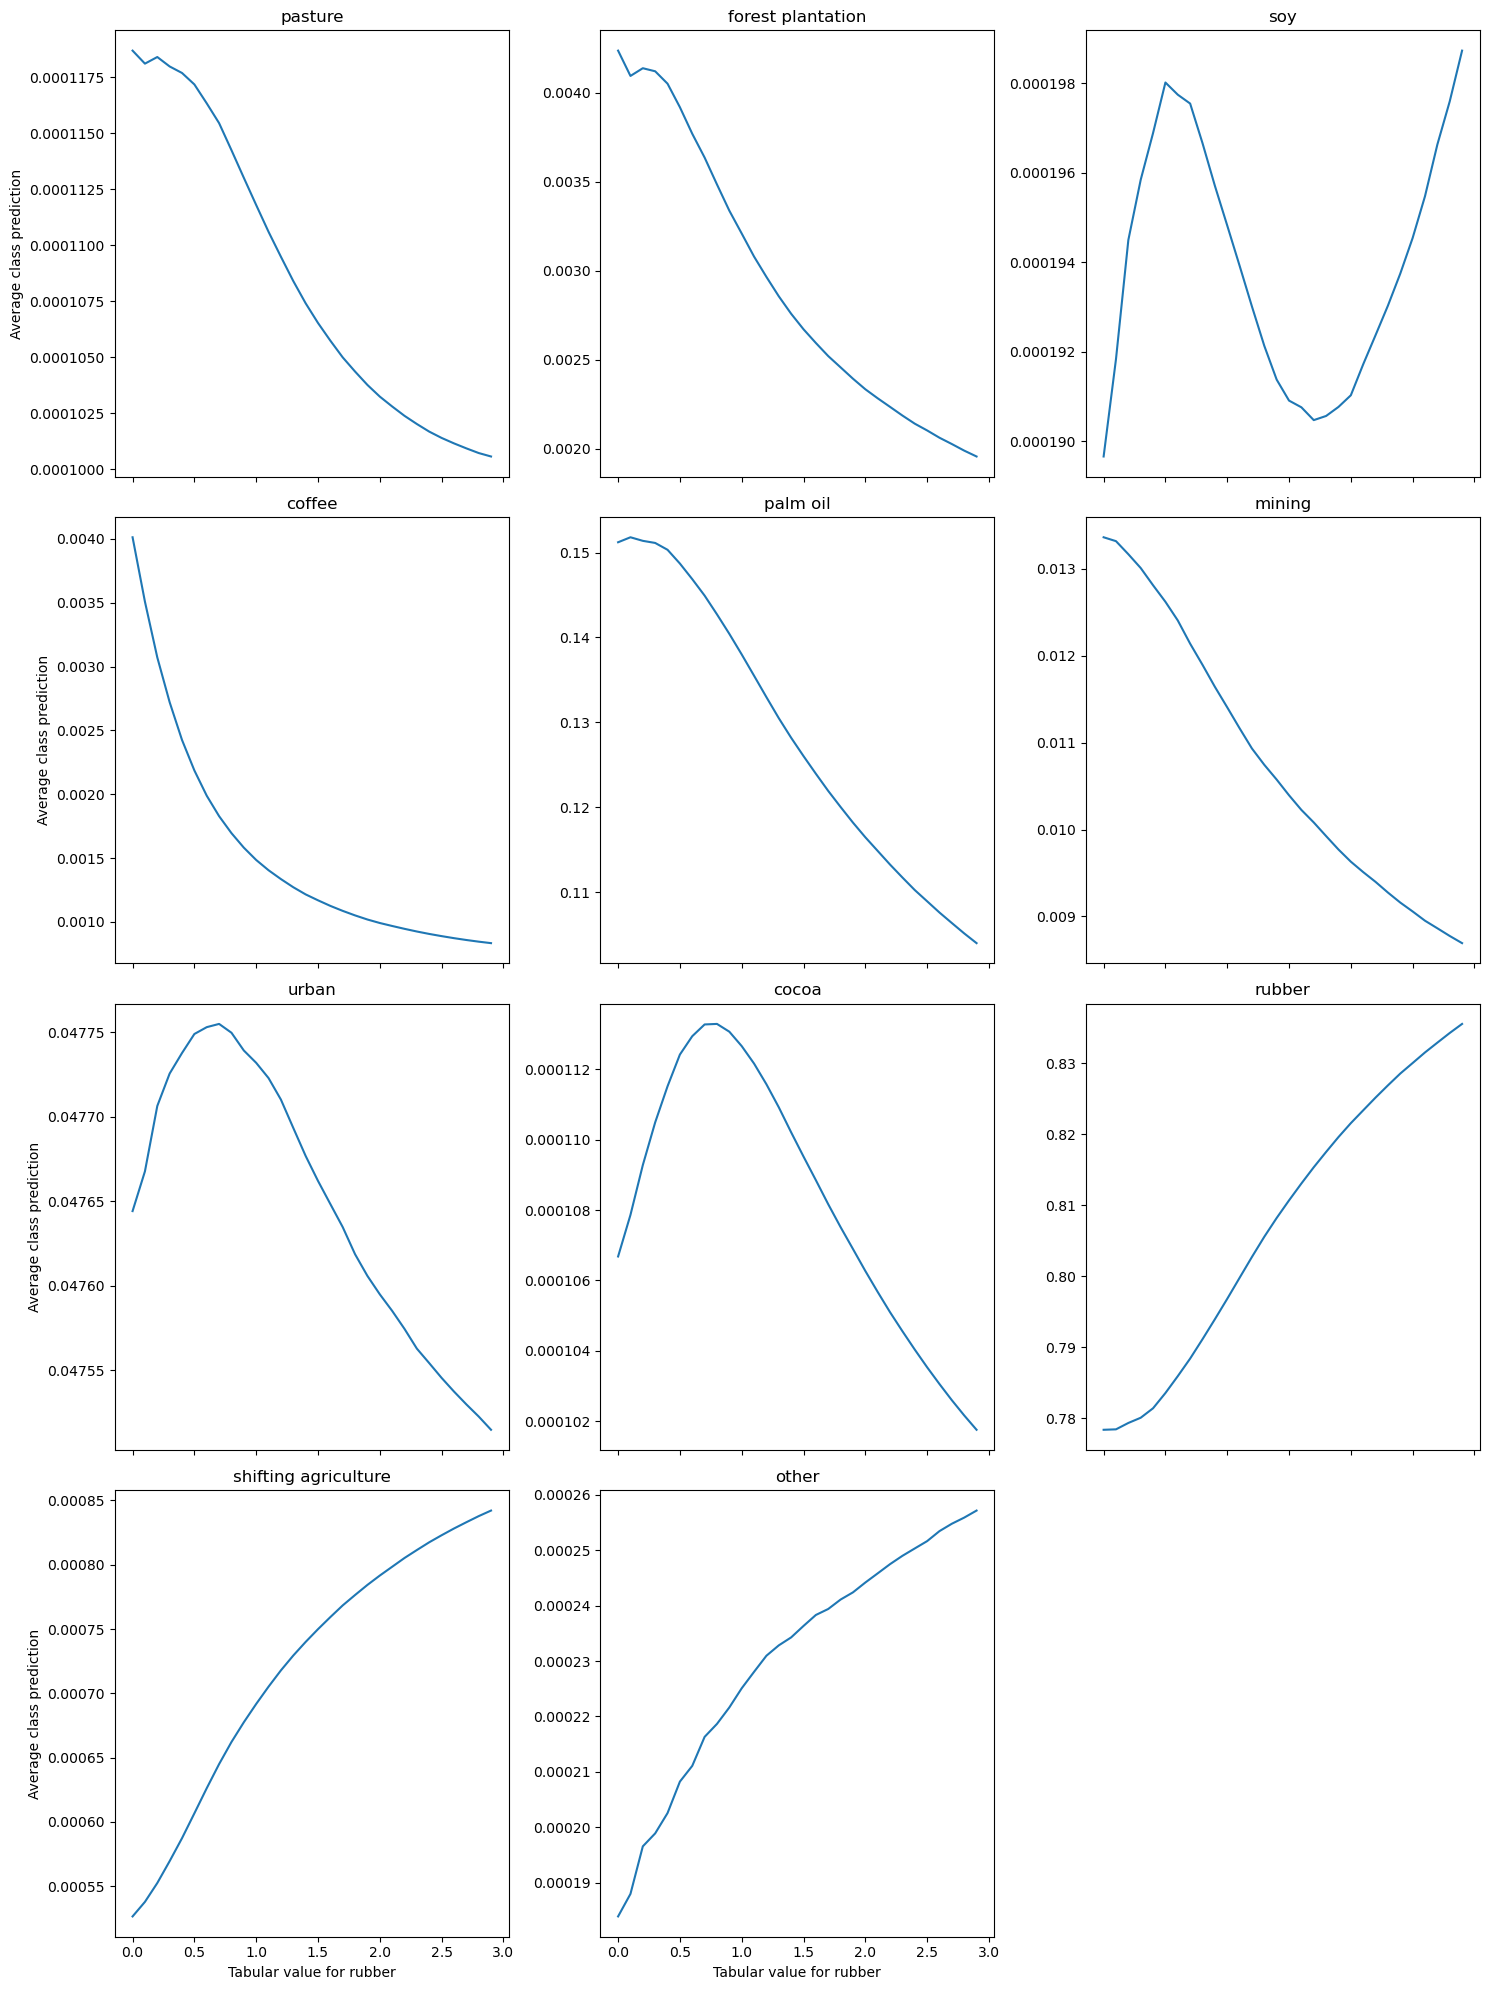

In [17]:

plot_all_classes(all_mean_probs, tab_values, 'rubber')

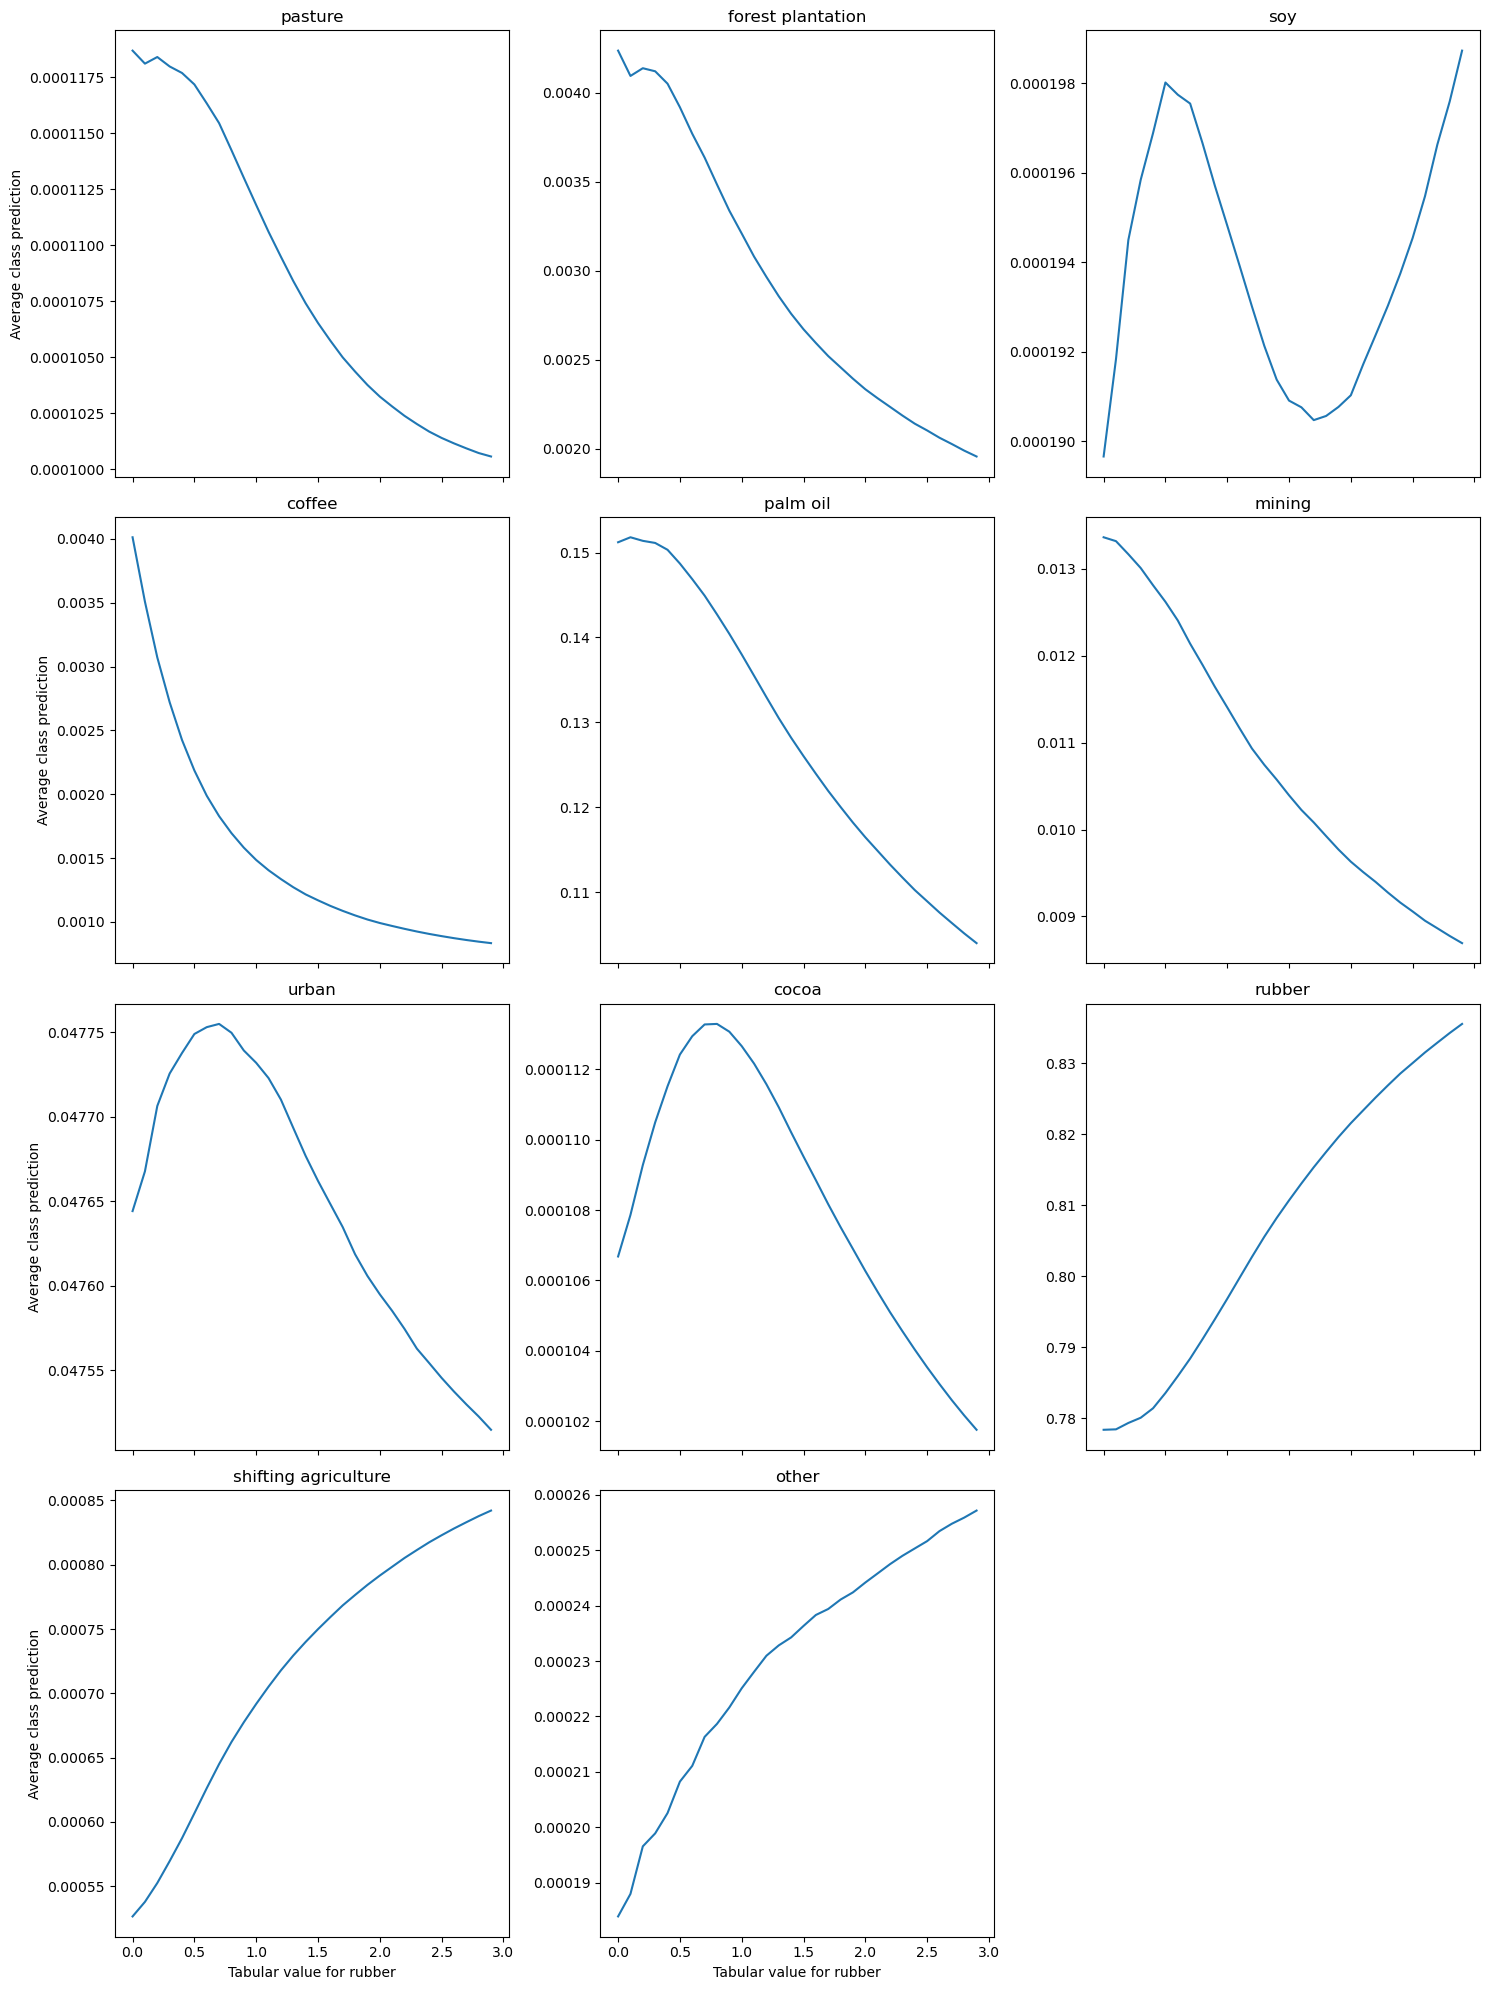

In [22]:

plot_all_classes(all_mean_probs, tab_values, 'rubber')

In [5]:
def plot_all_classes(probabilities, x_axis, class_name):

    # Adjust grid size as needed; here we're using a 4x3 grid to accommodate up to 12 subplots
    fig, axs = plt.subplots(4, 3, figsize=(15, 20), sharex=True)

    limits = {}

    #x_axis_vals = 

    # Loop through LABEL_MAPPING and plot each on its own subplot
    for idx, (name, cls_idx) in enumerate(LABEL_MAPPING.items()):
        row = idx // 3
        col = idx % 3
        axs[row, col].plot(x_axis, probabilities[:, cls_idx])
        axs[row, col].set_title(name)

        if idx in [0,3,6,9]:
            axs[row, col].set_ylabel('Average class prediction')
        if idx in [9,10,11]:
            axs[row, col].set_xlabel(f'Tabular value for {class_name}')

    # Hide any unused subplots if the grid has extra spaces
    for i in range(len(LABEL_MAPPING), 12):
        fig.delaxes(axs.flat[i])

    #plt.xlabel("Coefficients")
    plt.tight_layout()
    plt.show()


In [6]:
def plot_averaged_classes(probabilities, x_axis, class_name):


    # Adjust grid size for two subplots
    fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)

    # Separate 'rubber' and other classes
    target_cls_idx = LABEL_MAPPING.get(class_name)
    other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

    # Plot for 'rubber'
    axs[0].plot(x_axis, probabilities[:, target_cls_idx])
    axs[0].set_title(class_name)
    axs[0].set_ylabel('Average class prediction')
    axs[0].set_xlabel(f'Tabular value for {class_name}')

    # Plot for average of other classes
    average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)
    axs[1].plot(x_axis, average_probs)
    axs[1].set_title('Average of Other Classes')
    axs[1].set_xlabel(f'Tabular value for {class_name}')

    # Tight layout
    plt.tight_layout()
    plt.show()


In [7]:
def plot_averaged_classes(probabilities, x_axis, class_name):
    target_cls_idx = LABEL_MAPPING.get(class_name)
    other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

    target_probs = probabilities[:, target_cls_idx]
    average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

    # Create the figure and axes
    fig, ax1 = plt.subplots(figsize=(7, 5))

    # Plot target class probabilities
    ax1.plot(x_axis, target_probs, label=class_name, linestyle='-', linewidth=2, color='tab:orange')
    ax1.set_ylabel(f'{class_name} Prediction', fontsize=12, color='tab:orange')
    ax1.tick_params(axis='y', labelcolor='tab:orange')
    ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

    # Create a secondary y-axis for the average of other classes
    ax2 = ax1.twinx()
    ax2.plot(x_axis, average_probs, label='Average of Other Classes', linestyle='--', linewidth=2, color='tab:green')
    ax2.set_ylabel('Average of Other Classes', fontsize=12, color='tab:green')
    ax2.tick_params(axis='y', labelcolor='tab:green')

    # Set common x-axis label and title
    ax1.set_xlabel(f'Tabular Value for {class_name}', fontsize=12)
    fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

    # Add a combined legend
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=10, frameon=True)

    # Optimize layout
    fig.tight_layout()
    plt.show()

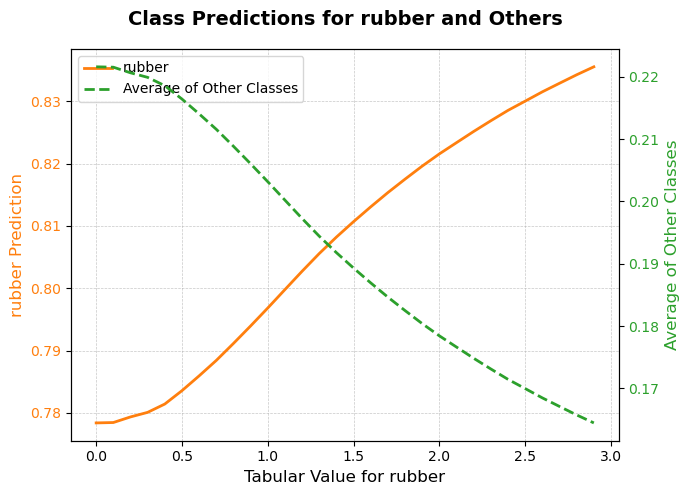

In [41]:
plot_averaged_classes(all_mean_probs, tab_values, 'rubber')

## Rubber final figure

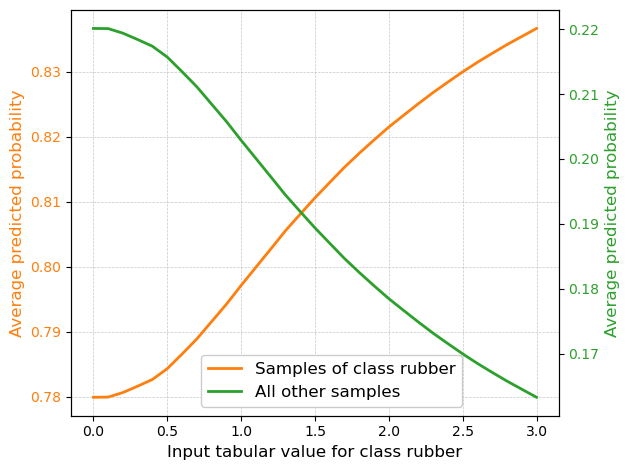

In [23]:

probabilities =all_mean_probs
x_axis = tab_values
class_name = 'rubber'


target_cls_idx = LABEL_MAPPING.get(class_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

target_probs = probabilities[:, target_cls_idx]
average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

# Create the figure and axes
fig, ax1 = plt.subplots(
    #figsize=(7, 5)
    )

# Plot target class probabilities
ax1.plot(x_axis, target_probs, label='Samples of class rubber', linestyle='-', linewidth=2, color='tab:orange')
ax1.set_ylabel('Average predicted probability', fontsize=12, color='tab:orange')

ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Create a secondary y-axis for the average of other classes
ax2 = ax1.twinx()
ax2.plot(x_axis, average_probs, label='All other samples', linewidth=2, color='tab:green')
ax2.set_ylabel('Average predicted probability', fontsize=12, color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# Set common x-axis label and title
ax1.set_xlabel(f'Input tabular value for class rubber', fontsize=12)
#fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

# Add a combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, bbox_to_anchor=(0.25,0.17), framealpha=1, fontsize=12)

# Optimize layout
fig.tight_layout()
plt.savefig('../paper/tabular_experiment_rubber.png', dpi=200, bbox_inches='tight')

plt.show()


## Mining

In [20]:
class_name = "mining"
# Separate 'rubber' and other classes
cls_idx = LABEL_MAPPING.get('mining')
tab_values = [coef/10 for coef in range(31)]

_preds_min, all_mean_probs_min = get_results(cls_idx, tabular_values=tab_values)

0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


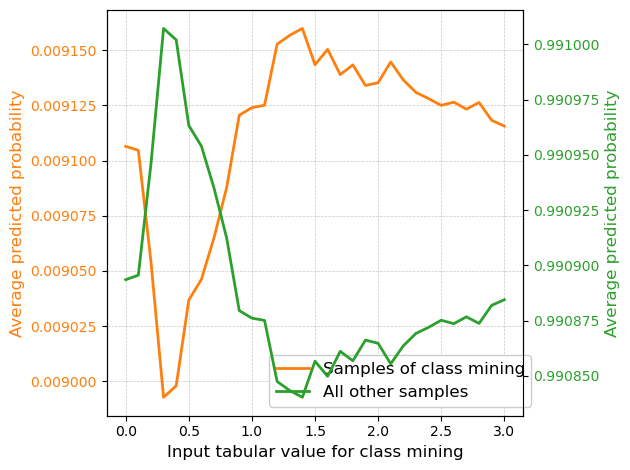

In [21]:

probabilities = all_mean_probs_min
x_axis = tab_values
class_name = 'mining'


target_cls_idx = LABEL_MAPPING.get(class_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

target_probs = probabilities[:, target_cls_idx]
average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

# Create the figure and axes
fig, ax1 = plt.subplots(
    #figsize=(7, 5)
    )

# Plot target class probabilities
ax1.plot(x_axis, target_probs, label='Samples of class mining', linestyle='-', linewidth=2, color='tab:orange')
ax1.set_ylabel('Average predicted probability', fontsize=12, color='tab:orange')

ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Create a secondary y-axis for the average of other classes
ax2 = ax1.twinx()
ax2.plot(x_axis, average_probs, label='All other samples', linewidth=2, color='tab:green')
ax2.set_ylabel('Average predicted probability', fontsize=12, color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# Set common x-axis label and title
ax1.set_xlabel(f'Input tabular value for class mining', fontsize=12)
#fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

# Add a combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, bbox_to_anchor=(0.37,0.17), framealpha=1, fontsize=12)

# Optimize layout
fig.tight_layout()
plt.savefig('../paper/tabular_experiment_mining.png', dpi=200, bbox_inches='tight')

plt.show()


## Coffee - Cambodia

In [19]:
class_name = "coffee"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, all_mean_probs_coffee = get_results(cls_idx, tabular_values=tab_values)


0.0
driver                                             rubber
sampleid                                         20013988
dataset                                        rubber.csv
country                                          Cambodia
geometry    POINT (105.50789368782931 12.497407111240468)
block_id                                             18.0
split                                                 val
dst_size                                              NaN
Name: 188, dtype: object
driver                                             rubber
sampleid                                         20014321
dataset                                        rubber.csv
country                                          Cambodia
geometry    POINT (105.52568033045492 12.372900613208593)
block_id                                             18.0
split                                                 val
dst_size                                              NaN
Name: 58, dtype: object
driver             

KeyboardInterrupt: 

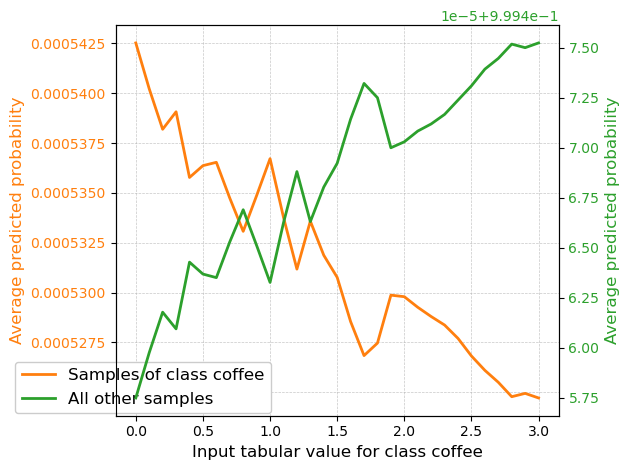

In [10]:

probabilities = all_mean_probs_coffee
x_axis = tab_values
class_name = 'coffee'


target_cls_idx = LABEL_MAPPING.get(class_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

target_probs = probabilities[:, target_cls_idx]
average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

# Create the figure and axes
fig, ax1 = plt.subplots(
    #figsize=(7, 5)
    )

# Plot target class probabilities
ax1.plot(x_axis, target_probs, label='Samples of class coffee', linestyle='-', linewidth=2, color='tab:orange')
ax1.set_ylabel('Average predicted probability', fontsize=12, color='tab:orange')

ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Create a secondary y-axis for the average of other classes
ax2 = ax1.twinx()
ax2.plot(x_axis, average_probs, label='All other samples', linewidth=2, color='tab:green')
ax2.set_ylabel('Average predicted probability', fontsize=12, color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# Set common x-axis label and title
ax1.set_xlabel(f'Input tabular value for class coffee', fontsize=12)
#fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

# Add a combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, bbox_to_anchor=(0.37,0.17), framealpha=1, fontsize=12)

# Optimize layout
fig.tight_layout()
#plt.savefig('../paper/tabular_experiment_mining.png', dpi=200, bbox_inches='tight')

plt.show()


In [12]:
class_name = "soy"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, all_mean_probs_soy = get_results(cls_idx, tabular_values=tab_values)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


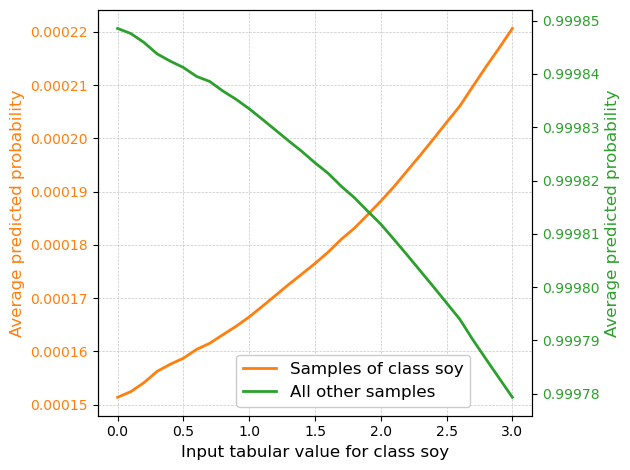

In [18]:

probabilities = all_mean_probs_soy
x_axis = tab_values
class_name = 'soy'


target_cls_idx = LABEL_MAPPING.get(class_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

target_probs = probabilities[:, target_cls_idx]
average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

# Create the figure and axes
fig, ax1 = plt.subplots(
    #figsize=(7, 5)
    )

# Plot target class probabilities
ax1.plot(x_axis, target_probs, label=f'Samples of class {class_name}', linestyle='-', linewidth=2, color='tab:orange')
ax1.set_ylabel('Average predicted probability', fontsize=12, color='tab:orange')

ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Create a secondary y-axis for the average of other classes
ax2 = ax1.twinx()
ax2.plot(x_axis, average_probs, label='All other samples', linewidth=2, color='tab:green')
ax2.set_ylabel('Average predicted probability', fontsize=12, color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# Set common x-axis label and title
ax1.set_xlabel(f'Input tabular value for class {class_name}', fontsize=12)
#fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

# Add a combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, bbox_to_anchor=(0.30,0.17), framealpha=1, fontsize=12)

# Optimize layout
fig.tight_layout()
plt.savefig('../paper/tabular_experiment_soy.png', dpi=200, bbox_inches='tight')

plt.show()


### COCOA - Cambodia

In [72]:
class_name = "cocoa"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, all_mean_probs_p = get_results(cls_idx, tabular_values=tab_values)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


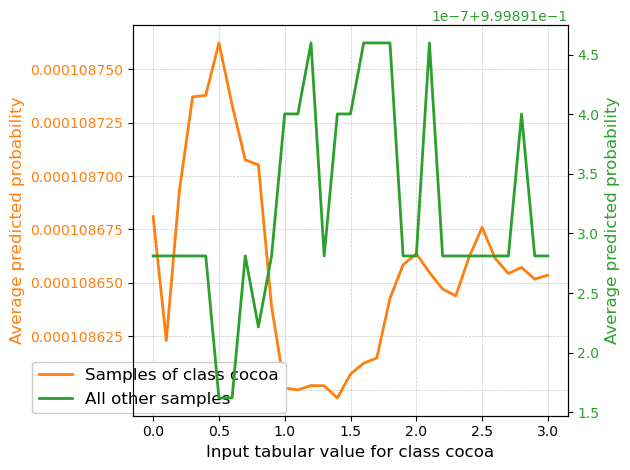

In [74]:

probabilities = all_mean_probs_p
x_axis = tab_values
class_name = 'cocoa'


target_cls_idx = LABEL_MAPPING.get(class_name)
other_classes_idx = [cls_idx for name, cls_idx in LABEL_MAPPING.items() if name != class_name]

target_probs = probabilities[:, target_cls_idx]
average_probs = np.mean(probabilities[:, other_classes_idx], axis=1)*10

# Create the figure and axes
fig, ax1 = plt.subplots(
    #figsize=(7, 5)
    )

# Plot target class probabilities
ax1.plot(x_axis, target_probs, label='Samples of class cocoa', linestyle='-', linewidth=2, color='tab:orange')
ax1.set_ylabel('Average predicted probability', fontsize=12, color='tab:orange')

ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(visible=True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Create a secondary y-axis for the average of other classes
ax2 = ax1.twinx()
ax2.plot(x_axis, average_probs, label='All other samples', linewidth=2, color='tab:green')
ax2.set_ylabel('Average predicted probability', fontsize=12, color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# Set common x-axis label and title
ax1.set_xlabel(f'Input tabular value for class cocoa', fontsize=12)
#fig.suptitle(f'Class Predictions for {class_name} and Others', fontsize=14, weight='bold')

# Add a combined legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, bbox_to_anchor=(0.37,0.16), framealpha=1, fontsize=12)

# Optimize layout
fig.tight_layout()
#plt.savefig('../paper/tabular_experiment_mining.png', dpi=200, bbox_inches='tight')

plt.show()


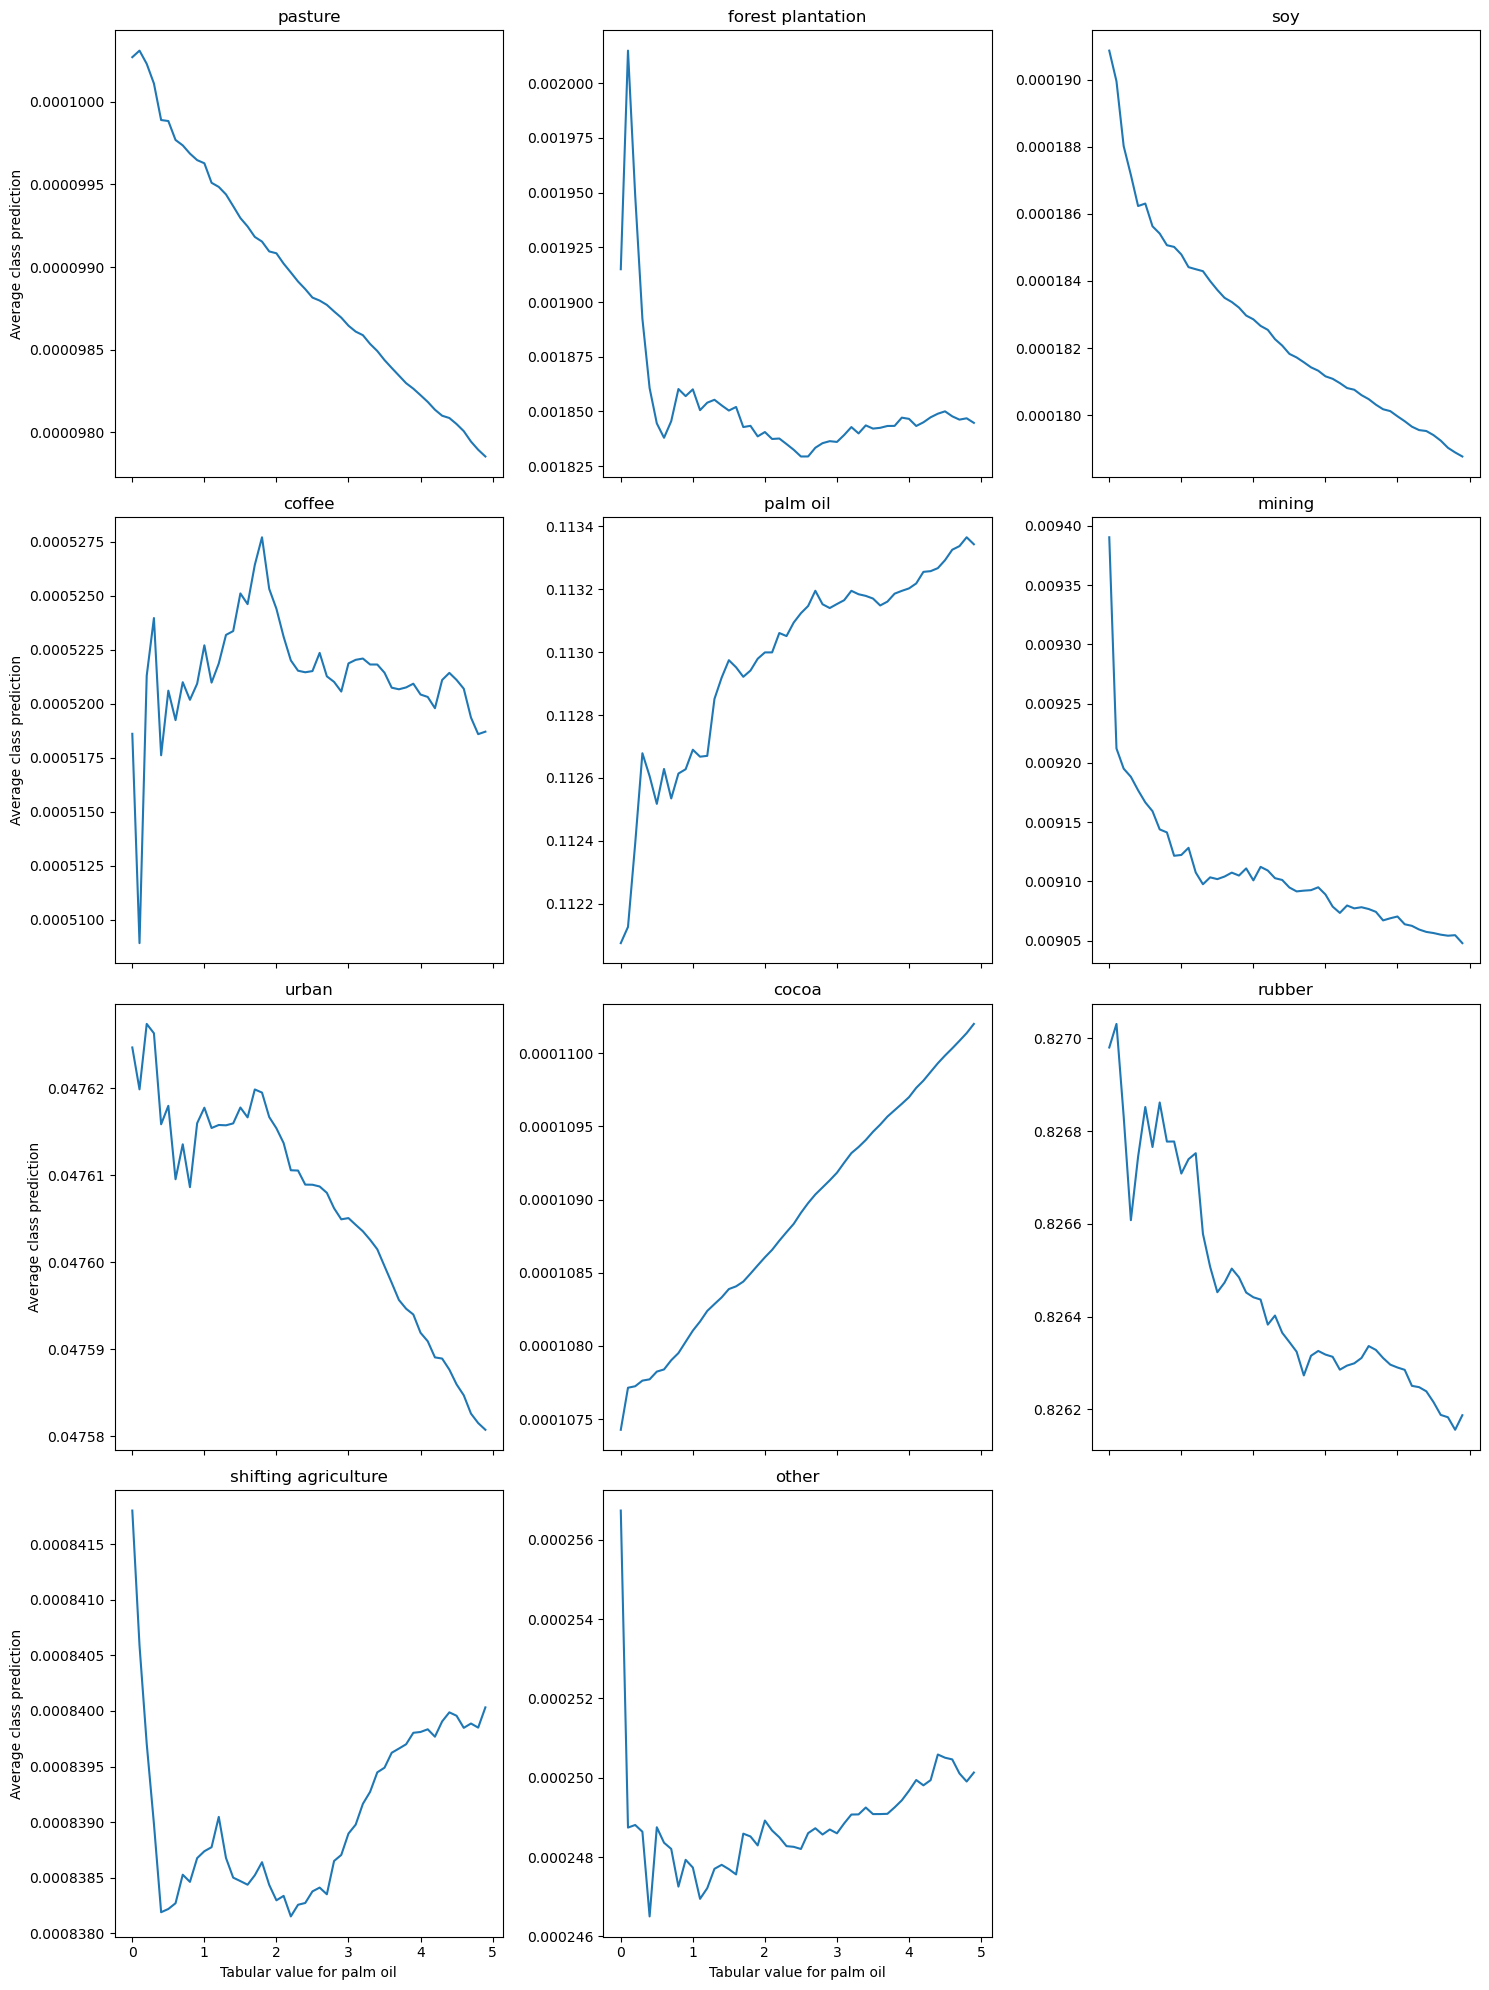

In [31]:
plot_all_classes(all_mean_probs, tab_values, class_name)


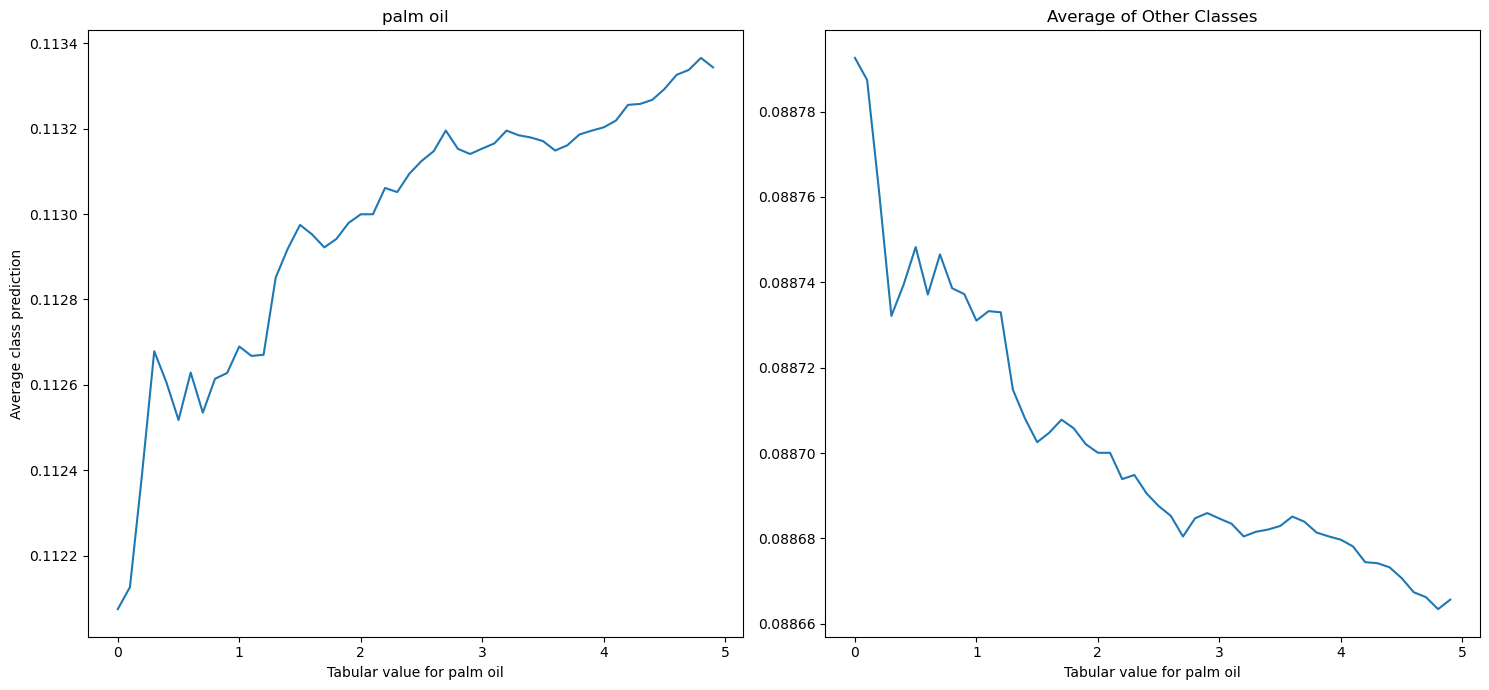

In [32]:

plot_averaged_classes(all_mean_probs, tab_values, class_name)

### Urban

In [33]:
class_name = "urban"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(50)]
_preds, all_mean_probs = get_results(cls_idx, tabular_values=tab_values)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9


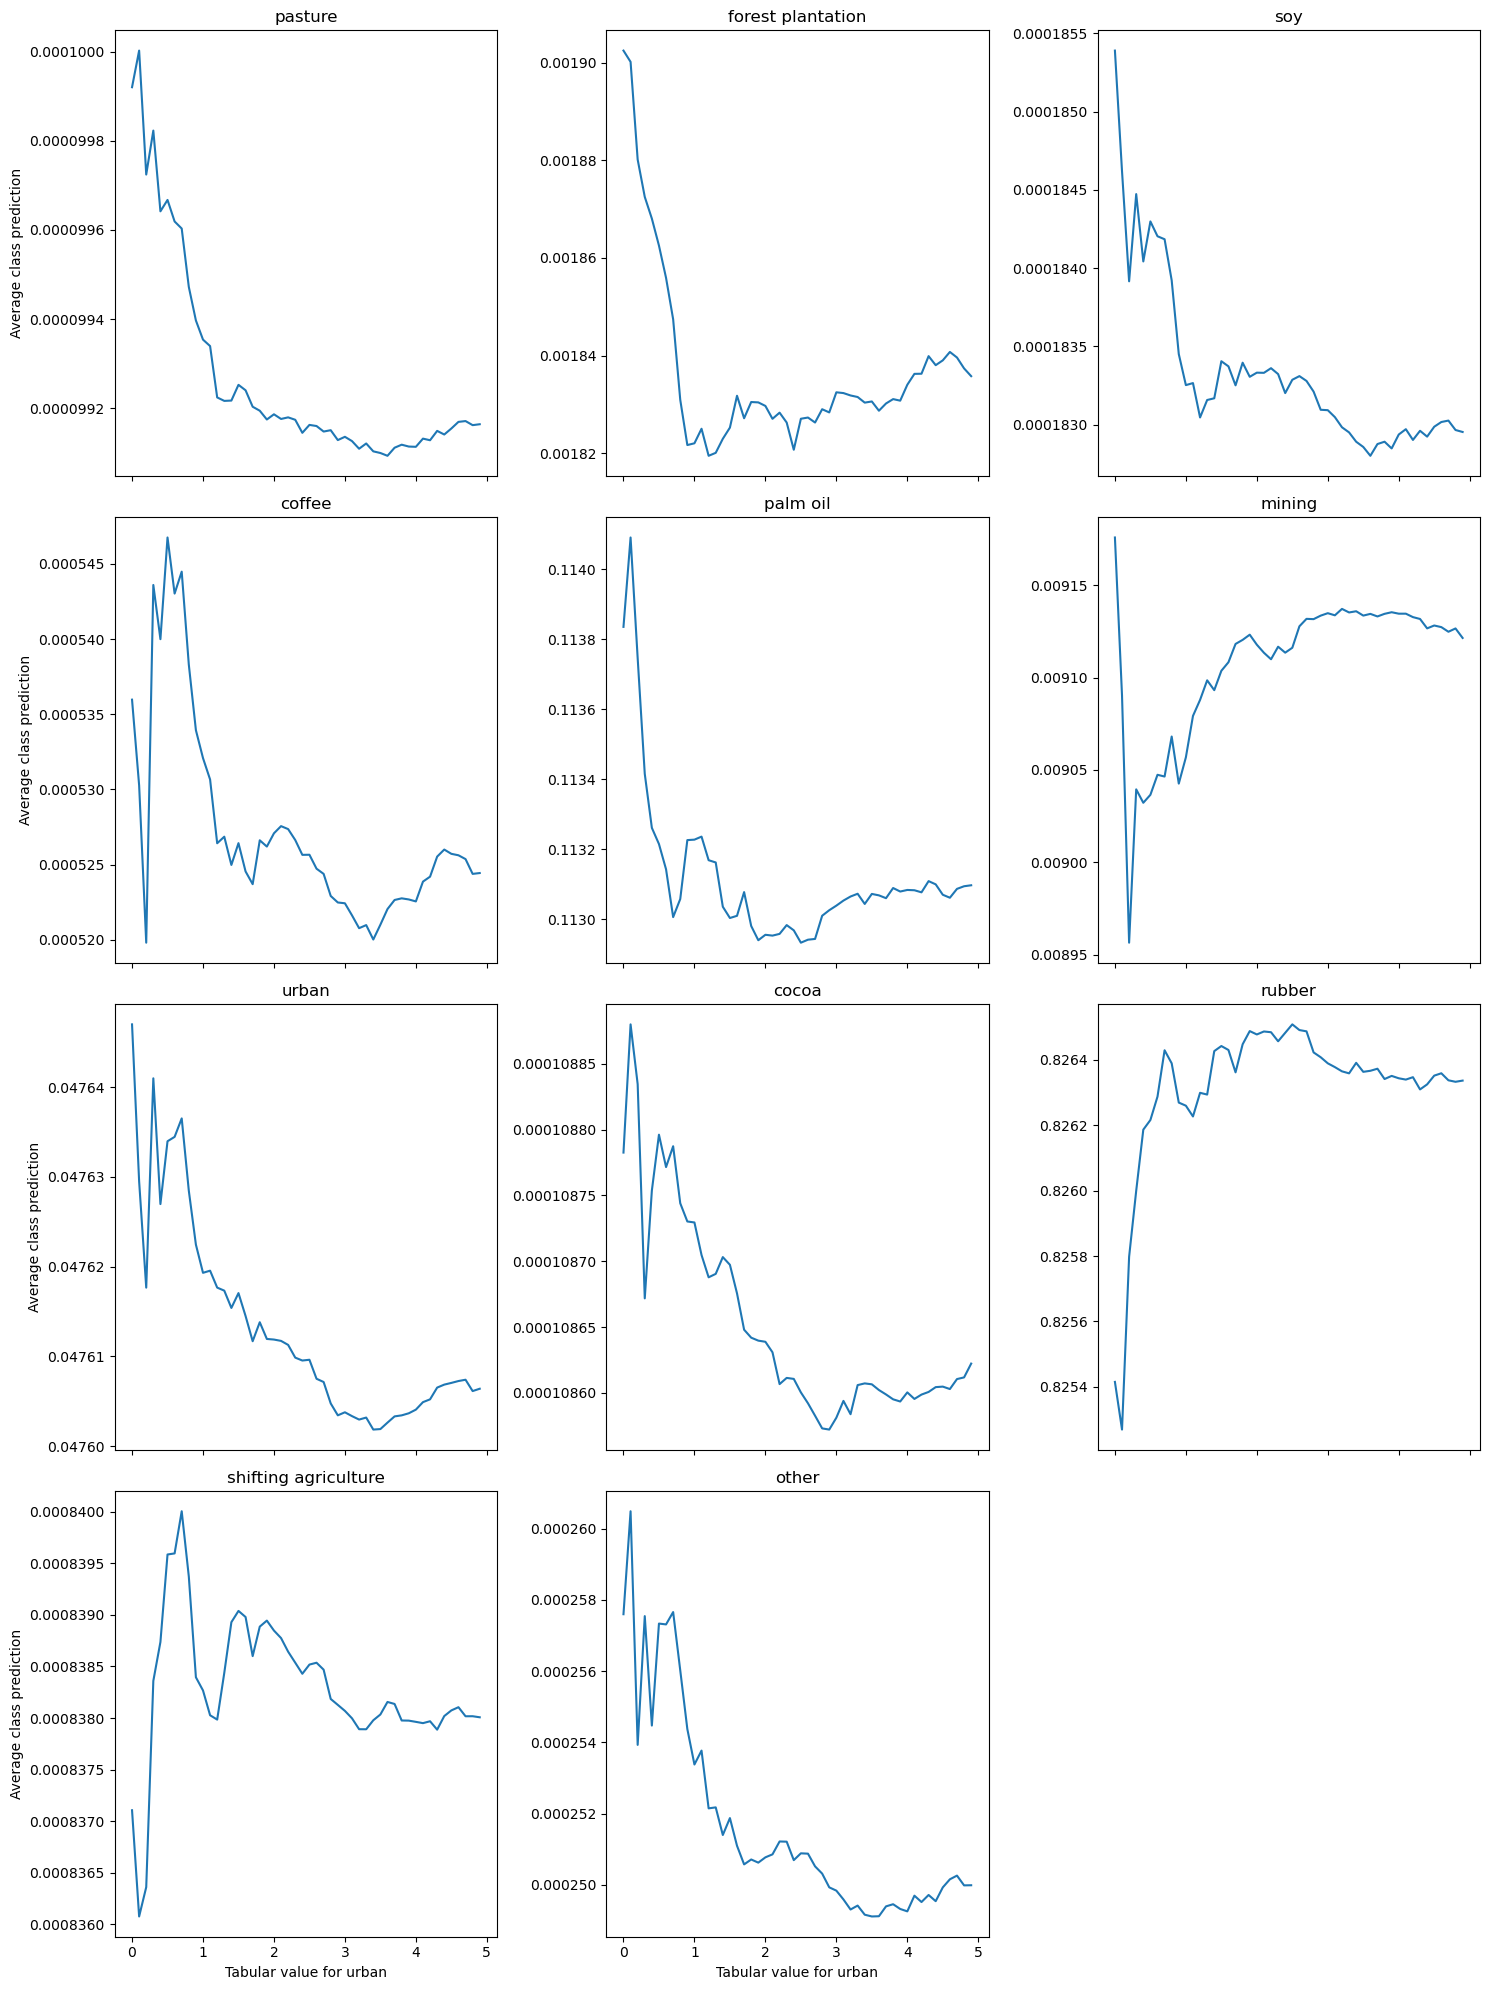

In [34]:
plot_all_classes(all_mean_probs, tab_values, class_name)



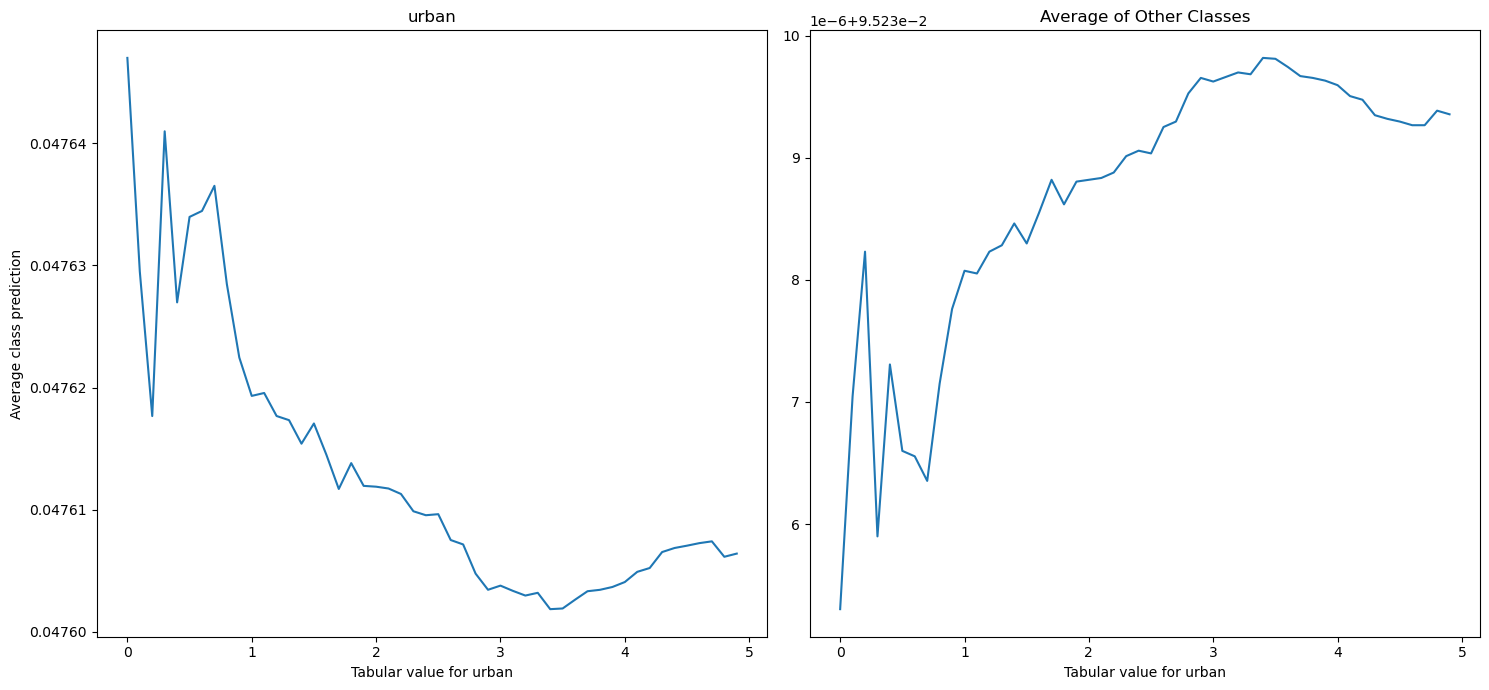

In [35]:
plot_averaged_classes(all_mean_probs, tab_values, class_name)

# Ghana

In [52]:
ghana

,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
2076,urban,100015773,worldcover.csv,Ghana,POINT (-1.7682749981795174 4.955034730598358),147.0,4,NaN
2077,urban,100015774,worldcover.csv,Ghana,POINT (-1.7593816768667343 4.955034730598358),147.0,4,NaN
2078,urban,100015775,worldcover.csv,Ghana,POINT (-1.9639280670607486 4.88388816031149),147.0,4,NaN
2079,urban,100015776,worldcover.csv,Ghana,POINT (-1.8305282473690014 4.88388816031149),147.0,4,NaN
2273,urban,100016245,worldcover.csv,Ghana,POINT (-1.5370486440471518 6.56767660094949),147.0,4,NaN
...,...,...,...,...,...,...,...,...
19259,palm oil,90167957,palm_oil.csv,Ghana,POINT (-2.3927076750165512 4.99872029896546),147.0,4,NaN
19263,palm oil,90099725,palm_oil.csv,Ghana,POINT (-0.9607931121300338 6.243875110531239),147.0,4,NaN
19264,palm oil,90099836,palm_oil.csv,Ghana,POINT (-1.1920194662623975 5.879248937802525),147.0,4,NaN
20986,palm oil,90167904,palm_oil.csv,Ghana,POINT (-1.9302549667518212 5.149906760825495),147.0,4,NaN


In [75]:
ghana = df.loc[df.country == 'Ghana']
ghana.to_csv('../data/tmp/ghana_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/ghana_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [76]:
def predict(model, dataloader):
    
    model.eval()

    preds_batches = []
    targets_batches = []

    for data_batch, labels_batch in dataloader:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)
        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)
        
    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()

    preds = probabilities.argmax(dim=1).numpy()
    
    return probabilities.numpy(), preds

In [49]:
probs, preds = predict(model, val_dl)

In [54]:
np.unique(preds, return_counts=True)

(array([4, 5, 6, 7, 9]), array([   9,   55,   45, 1057,   27]))

## Rubber

In [86]:
class_name = "rubber"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, _preds_rubber_ghana = get_results(cls_idx, tabular_values=tab_values, val_dl=val_dl)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


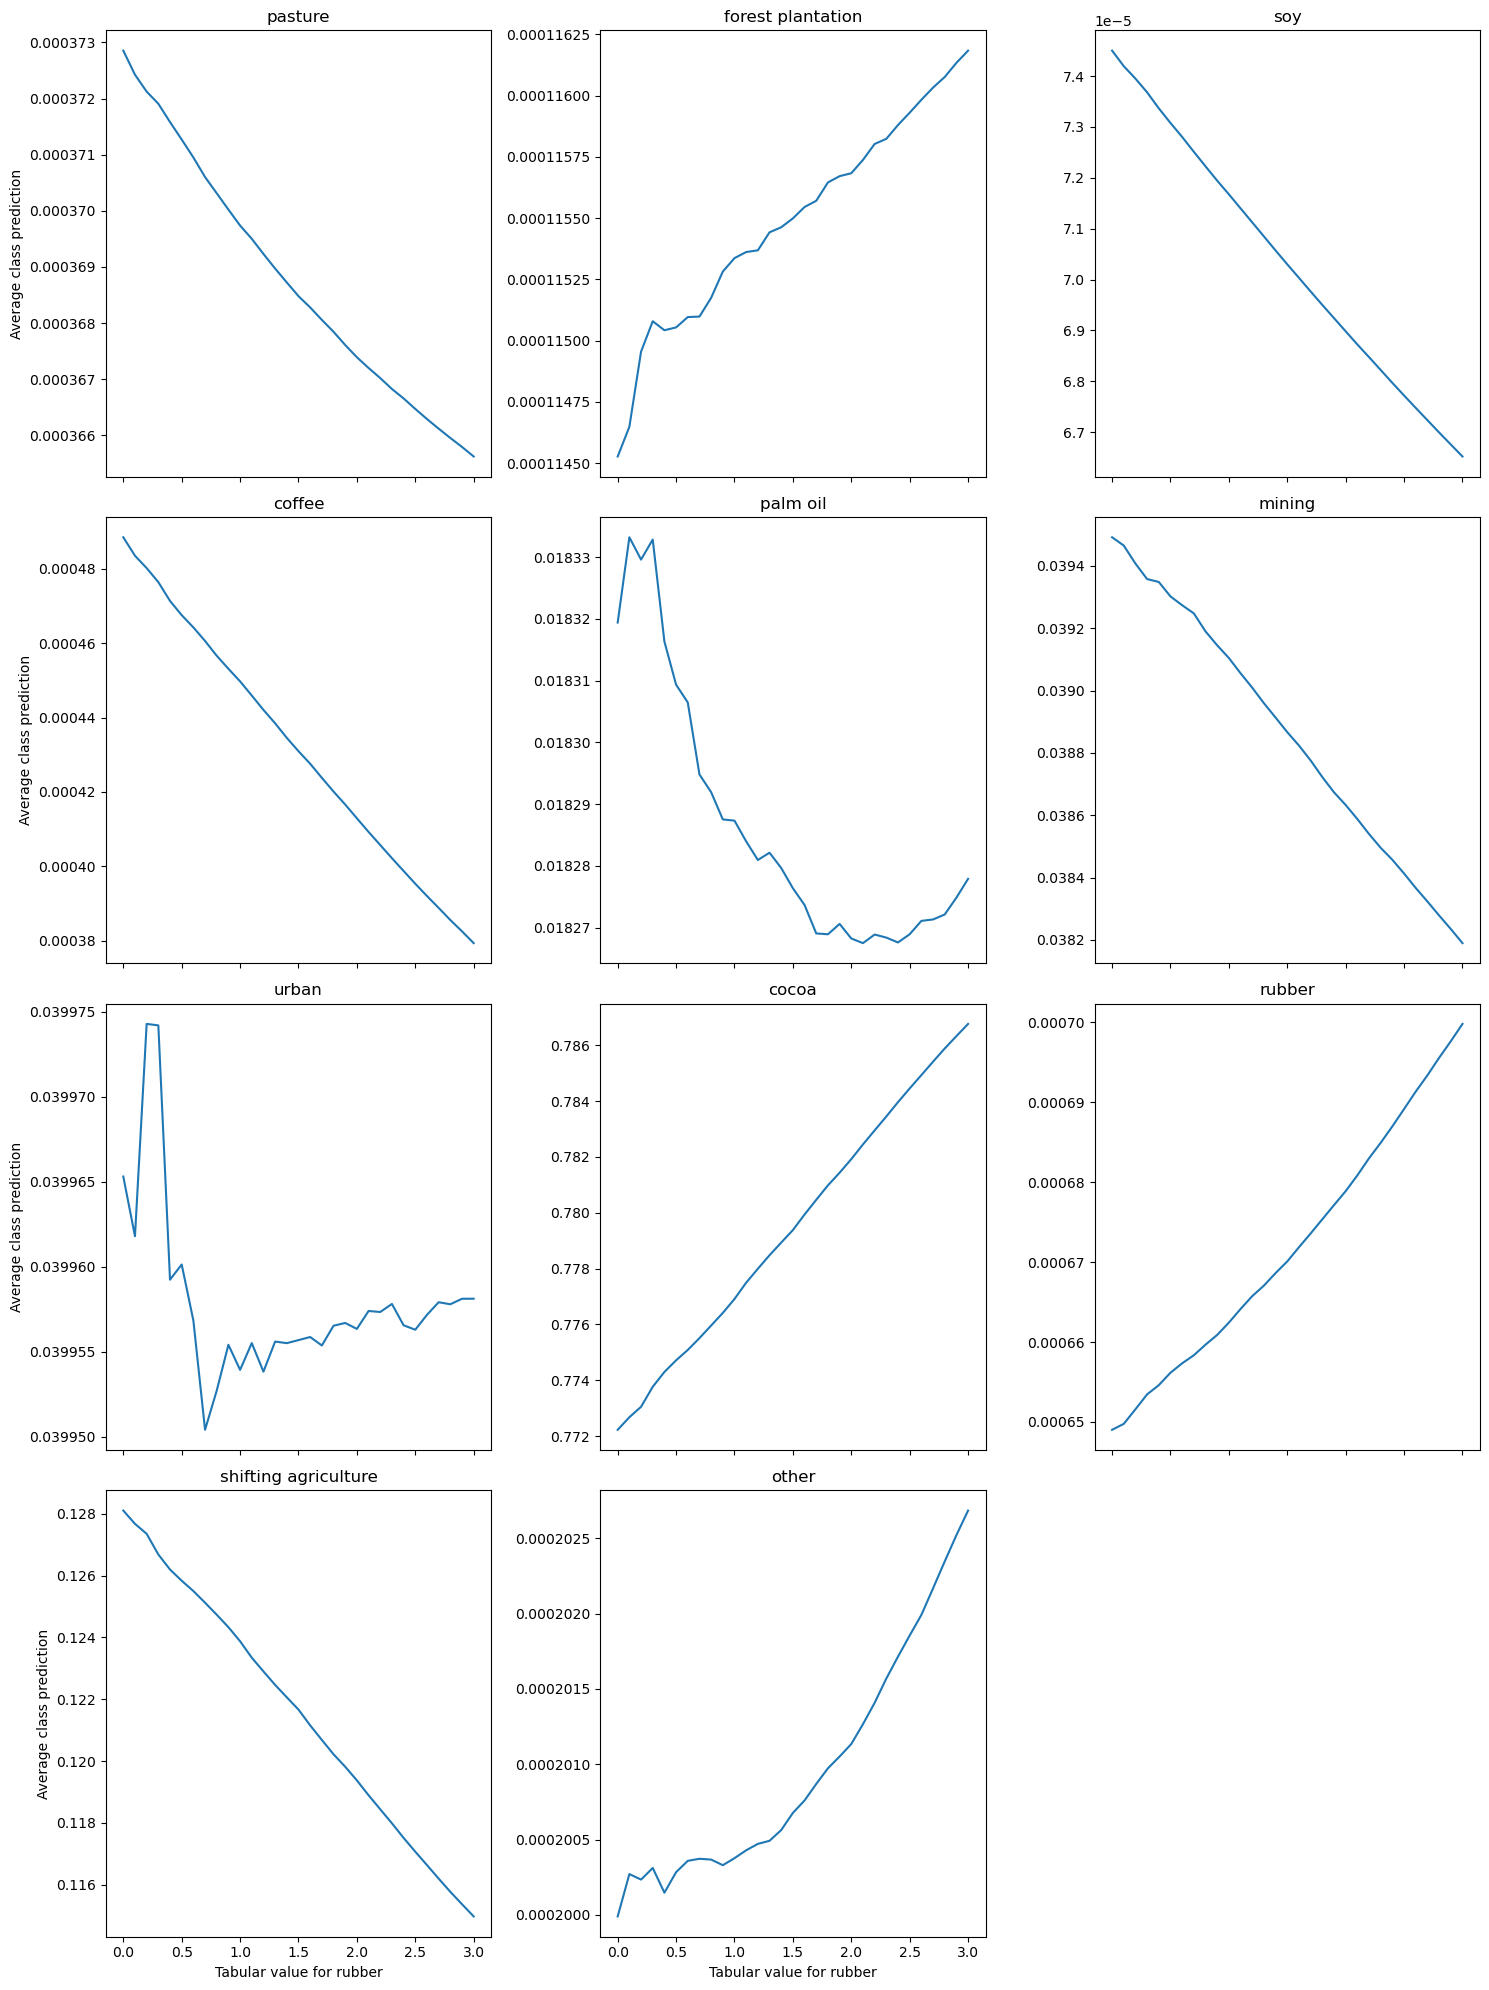

In [87]:
plot_all_classes(_preds_rubber_ghana, tab_values, class_name)




### Palm oil

In [82]:
class_name = "palm oil"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, _preds_palm_gh = get_results(cls_idx, tabular_values=tab_values, val_dl=val_dl)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


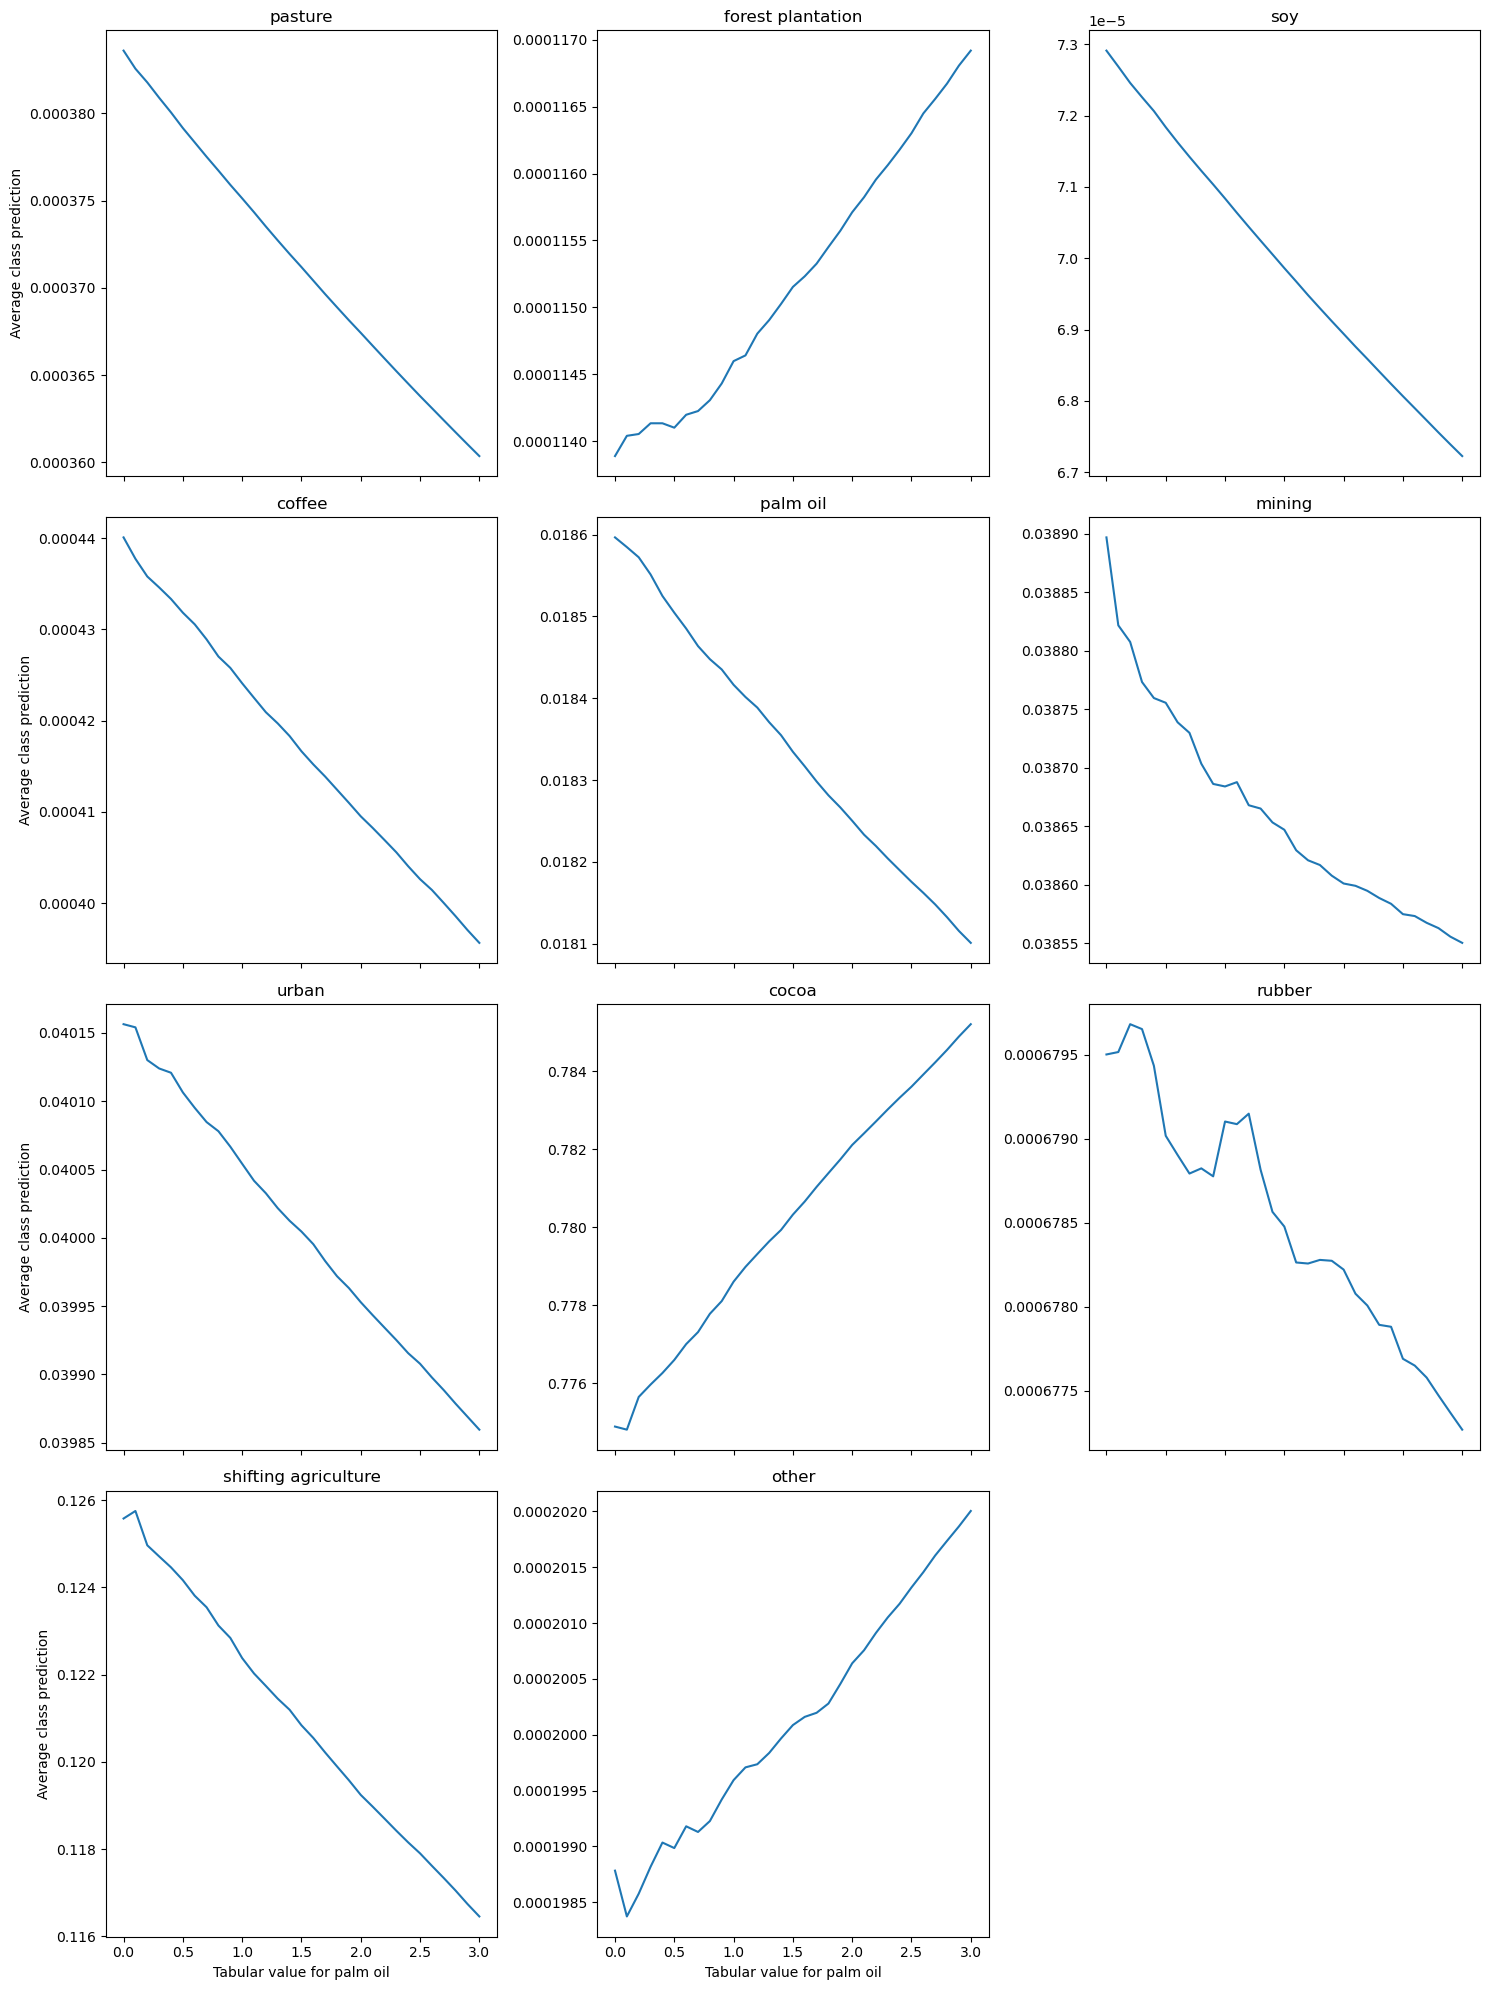

In [85]:
plot_all_classes(all_mean_probs, tab_values, class_name)




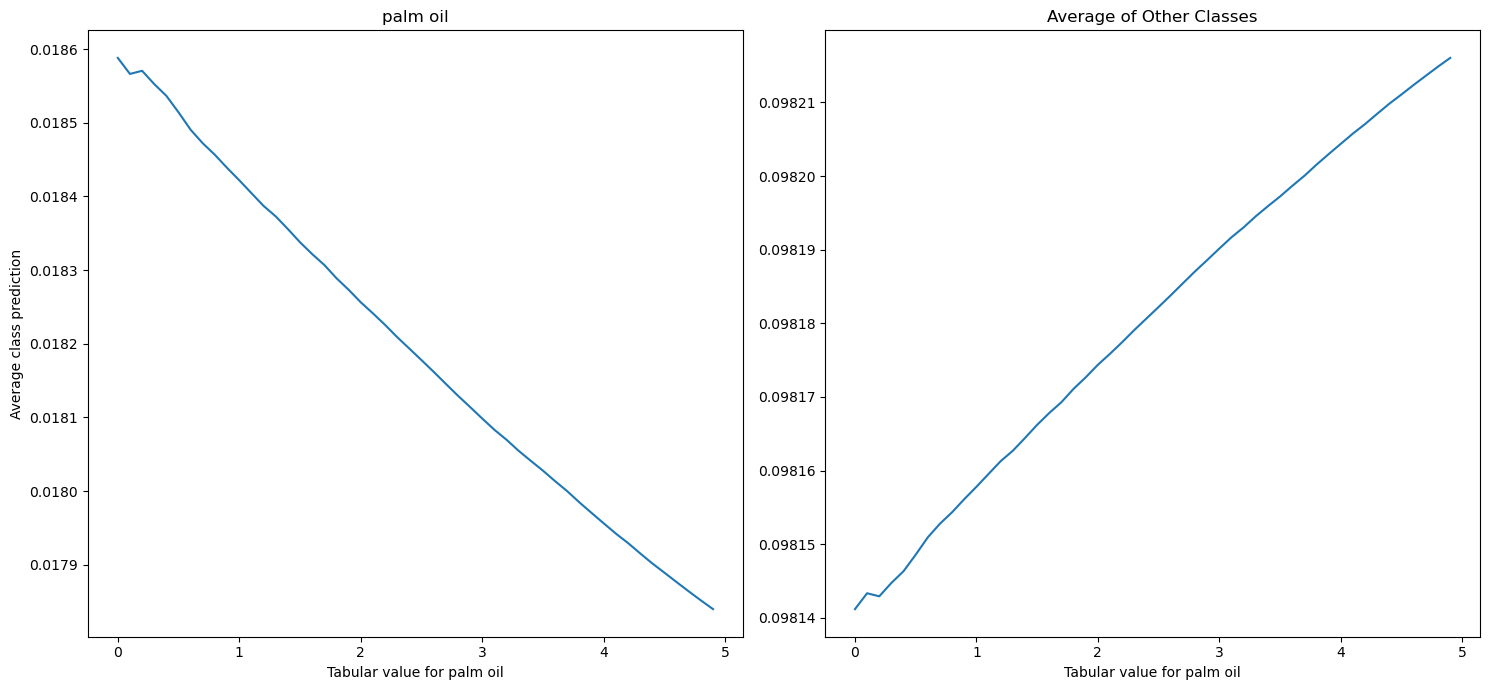

In [59]:
plot_averaged_classes(all_mean_probs, tab_values, class_name)

### Cocoa

In [77]:
class_name = "cocoa"
cls_idx = LABEL_MAPPING.get(class_name)
tab_values = [coef/10 for coef in range(31)]
_, all_mean_probs_gh_coco = get_results(cls_idx, tabular_values=tab_values, val_dl=val_dl)


0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0


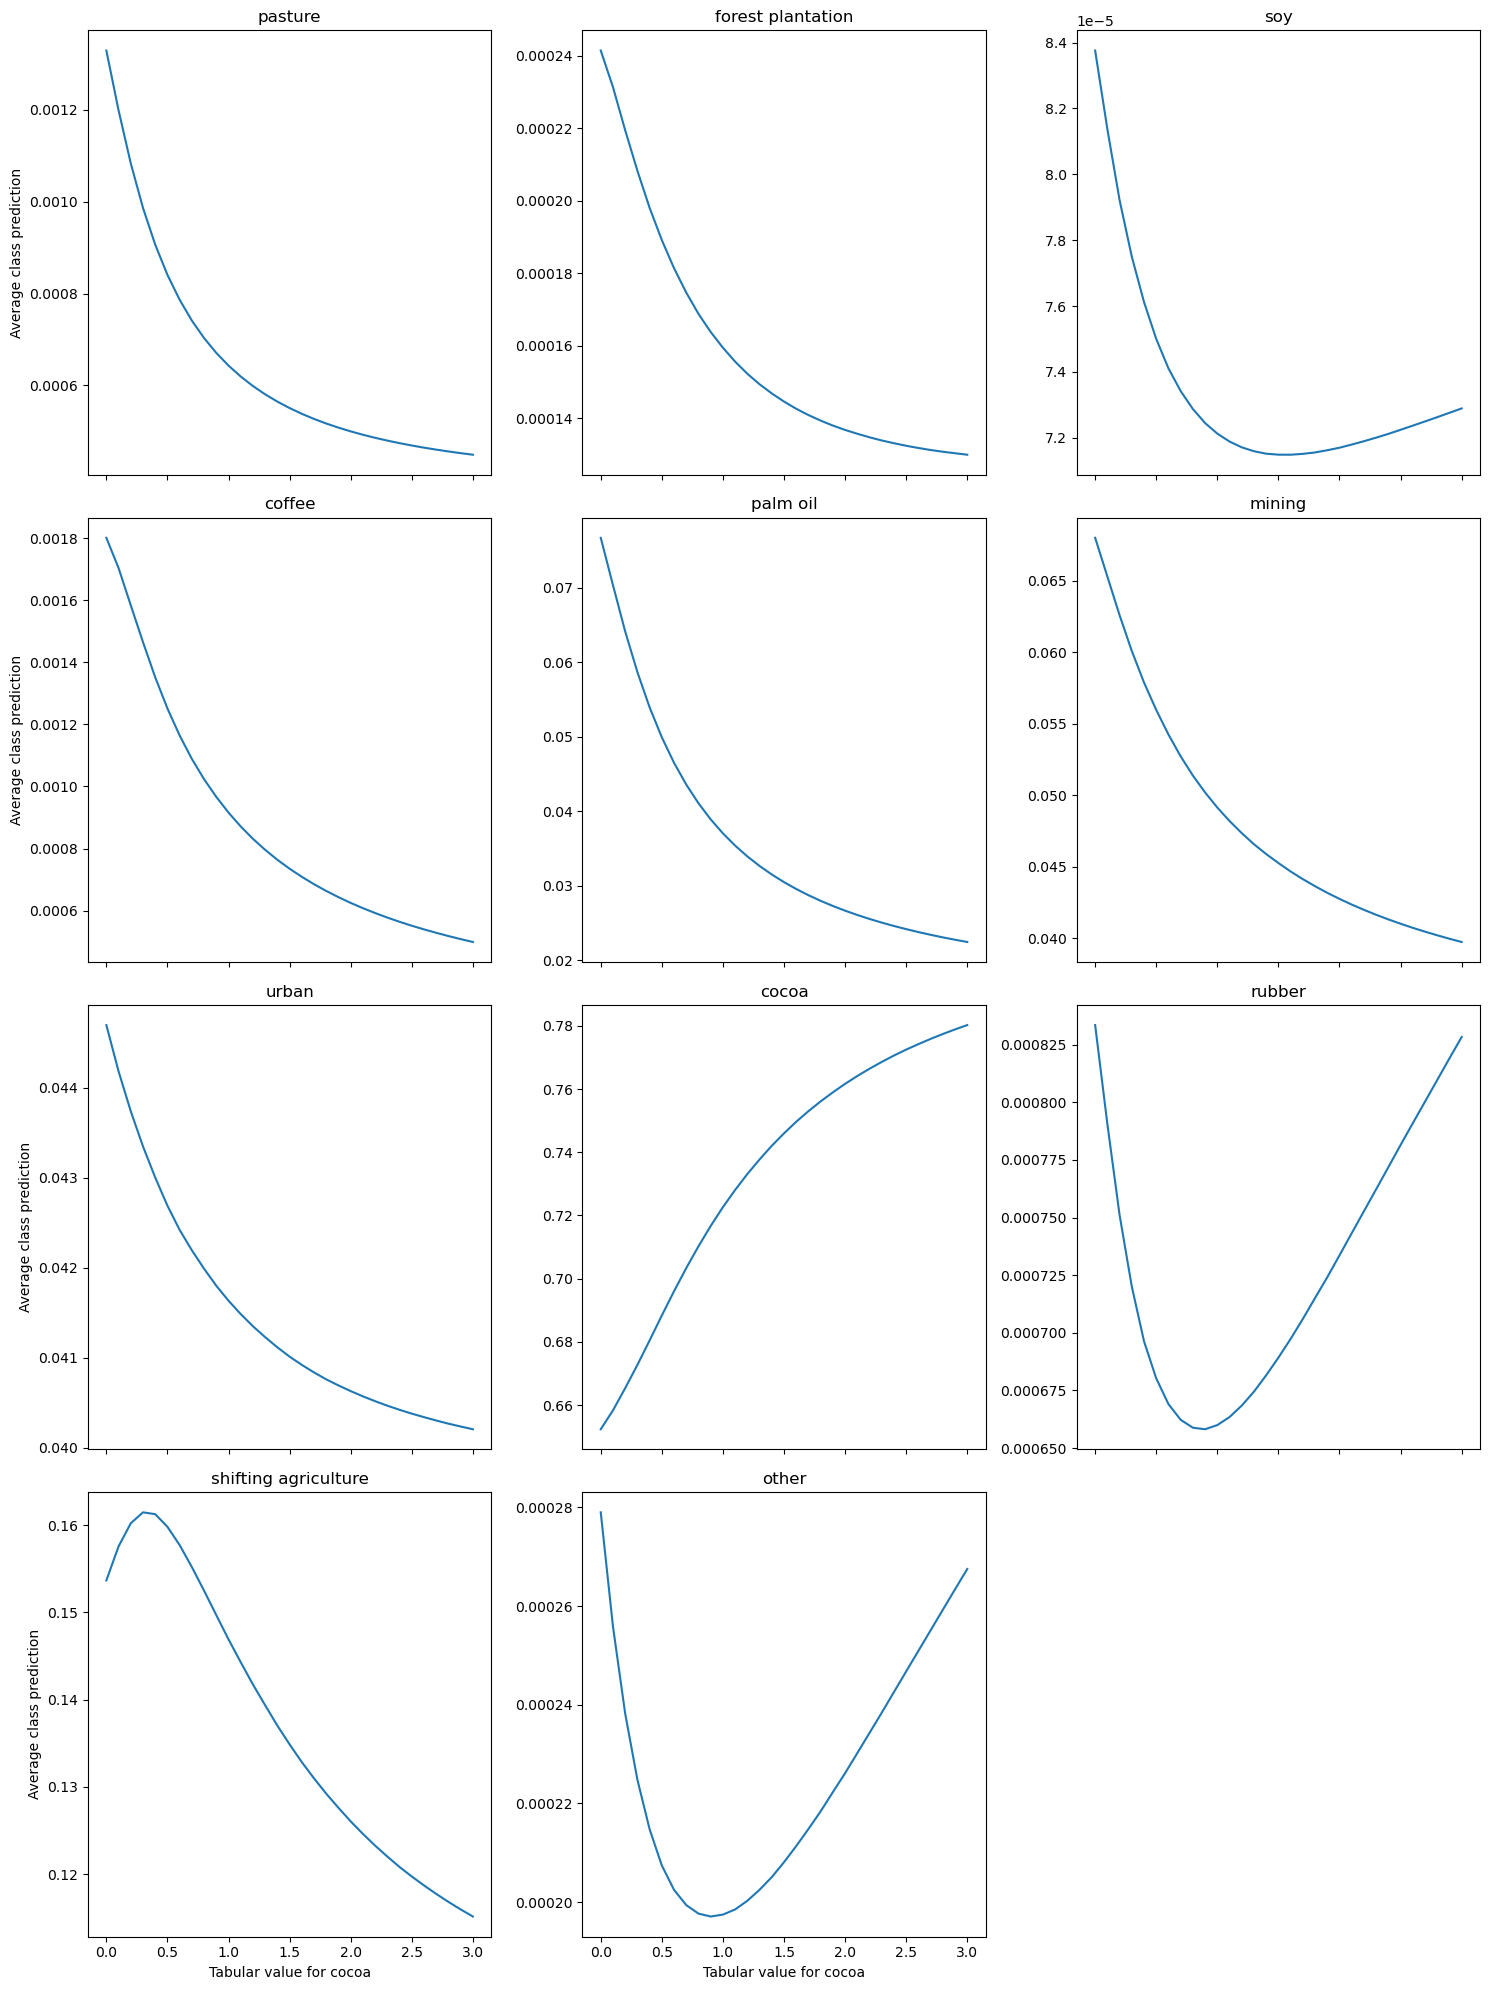

In [78]:
plot_all_classes(all_mean_probs_gh_coco, tab_values, class_name)




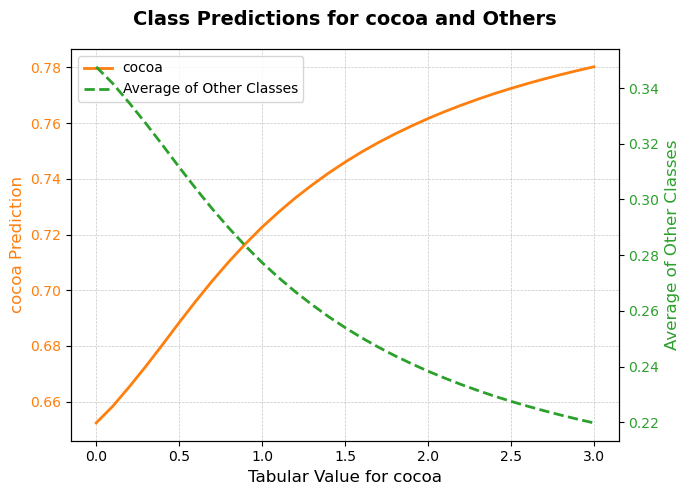

In [81]:
plot_averaged_classes(all_mean_probs_gh_coco, tab_values, class_name)

## Entire test set 

In [62]:

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())
    
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [ ]:
print(val_dl.dataset.img_labels.)

# Brazil

In [106]:
brazil = df.loc[df.country == 'Brazil']
brazil.to_csv('../data/tmp/brazil_tmp.csv',   index=False)
config['data']['annotation_file'] = '../data/tmp/brazil_tmp.csv'
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

### Cocoa